Los accidentes de 2023 no se repartieron al azar: se concentran en pocos equipos, y esa concentración se relaciona con la zona de salida (mitad de parrilla hacia atrás).

In [87]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency
import seaborn as sns
import matplotlib.pyplot as plt

In [88]:
results_23 = pd.read_csv('../data/results_23.csv')
constructors_23 = pd.read_csv('../data/constructors_23.csv')

In [89]:
results_23 = results_23.merge(
    constructors_23[['constructorId', 'constructorRef', 'name']],
    on='constructorId',
    how='left'
)
#results_23 = results_23.drop(columns=['constructorRef_x', 'name_x', 'constructorRef_y', 'name_y'])
results_23.info()

accidentes_23 = results_23[results_23['statusGeneric'] == 'Accident'].copy()
accidentes_23.info()

<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 21 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         440 non-null    int64  
 1   raceId           440 non-null    int64  
 2   driverId         440 non-null    int64  
 3   constructorId    440 non-null    int64  
 4   number           440 non-null    int64  
 5   grid             440 non-null    int64  
 6   position         440 non-null    str    
 7   positionText     440 non-null    str    
 8   positionOrder    440 non-null    int64  
 9   points           440 non-null    float64
 10  laps             440 non-null    int64  
 11  time             440 non-null    str    
 12  milliseconds     440 non-null    str    
 13  fastestLap       440 non-null    str    
 14  rank             440 non-null    int64  
 15  fastestLapTime   440 non-null    str    
 16  fastestLapSpeed  440 non-null    str    
 17  statusId         440 non-nu

In [90]:
# 1. Ver columnas de resultados_23 (antes del filtro)
print("Columnas en results_23:", results_23.columns.tolist())

# 2. Ver columnas de constructores_23
print("\nColumnas en constructors_23:", constructors_23.columns.tolist())

# 3. Ver columnas de accidentes_23 (después del filtro)
print("\nColumnas en accidentes_23:", accidentes_23.columns.tolist())

Columnas en results_23: ['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'position', 'positionText', 'positionOrder', 'points', 'laps', 'time', 'milliseconds', 'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed', 'statusId', 'statusGeneric', 'constructorRef', 'name']

Columnas en constructors_23: ['constructorId', 'constructorRef', 'name', 'nationality']

Columnas en accidentes_23: ['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'position', 'positionText', 'positionOrder', 'points', 'laps', 'time', 'milliseconds', 'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed', 'statusId', 'statusGeneric', 'constructorRef', 'name']


In [91]:
# 1. Crear columna 'zona' (cuartos de parrilla)
bins = [0, 5, 10, 15, 21]  # 2023 tiene 20 coches, pero por si hay grid=21/22 en datos
labels = ['Zona 1 (1-5)', 'Zona 2 (6-10)', 'Zona 3 (11-15)', 'Zona 4 (16-20)']
accidentes_23['zona'] = pd.cut(accidentes_23['grid'], bins=bins, labels=labels, right=False, include_lowest=True)

# 2. Accidentes por equipo (conteo absoluto)
accidentes_por_equipo = accidentes_23['name'].value_counts().sort_values(ascending=False)

# 3. % de accidentes por equipo (para concentración)
total_accidentes = len(accidentes_23)
accidentes_por_equipo_pct = (accidentes_por_equipo / total_accidentes * 100).round(1)

# 4. Verificar criterio 2: Top-3 equipos acumulan ≥ 50%?
top3_pct = accidentes_por_equipo_pct.head(3).sum()
print(f"Top-3 equipos: {accidentes_por_equipo.index[:3].tolist()} con {top3_pct:.1f}% de los accidentes")
print(f"Criterio 1 (Top-3 ≥ 50%): {'CUMPLE' if top3_pct >= 50 else 'NO CUMPLE'}")

Top-3 equipos: ['Alpine F1 Team', 'Williams', 'Haas F1 Team'] con 48.5% de los accidentes
Criterio 1 (Top-3 ≥ 50%): NO CUMPLE


### Declaración metodológica: Salidas desde pit lane
En 2023 hay 5 casos con `grid=0` (salida desde pit lane). Estos casos se asignan a la **mitad trasera de la parrilla** (posiciones 11-20).
Justificación: El pit lane se considera equivalente a la última posición de salida, ya que los coches que salen desde boxes lo hacen después de que el resto haya recibido la señal de inicio.

In [92]:
print("\n--- Desglose completo de accidentes por equipo ---")
print(accidentes_por_equipo_pct)


--- Desglose completo de accidentes por equipo ---
name
Alpine F1 Team    18.2
Williams          18.2
Haas F1 Team      12.1
AlphaTauri         9.1
Ferrari            9.1
Aston Martin       9.1
McLaren            6.1
Alfa Romeo         6.1
Mercedes           6.1
Red Bull           6.1
Name: count, dtype: float64


In [93]:
# --- CRITERIO 2: Chi-cuadrado (¿los accidentes NO se reparten al azar?) ---
# 1. Salidas por equipo (denominador)
salidas_por_equipo = results_23['name'].value_counts()

# 2. Accidentes observados por equipo
accidentes_observados = accidentes_por_equipo.reindex(salidas_por_equipo.index, fill_value=0)

# 3. Accidentes esperados (proporcional a salidas)
total_salidas = salidas_por_equipo.sum()
total_accidentes = accidentes_observados.sum()
accidentes_esperados = (salidas_por_equipo / total_salidas) * total_accidentes

# 4. Test chi-cuadrado
chi2, p_value, _, _ = chi2_contingency(
    pd.DataFrame({'Observados': accidentes_observados, 'Esperados': accidentes_esperados}).T
)

print("=== CRITERIO 2: Chi-cuadrado ===")
print(f"p-value: {p_value:.4f}")
print(f"Criterio 2 (p < 0.05): {'CUMPLE' if p_value < 0.05 else 'NO CUMPLE'}")

=== CRITERIO 2: Chi-cuadrado ===
p-value: 0.9661
Criterio 2 (p < 0.05): NO CUMPLE


In [94]:
# --- CRITERIO 3: Gradiente (mitad trasera vs. delantera) ---
# 1. Accidentes por zona
accidentes_por_zona = accidentes_23['zona'].value_counts().reindex(labels, fill_value=0)

# 2. Salidas por zona (denominador)
salidas_por_zona = results_23['grid'].apply(
    lambda x: pd.cut([x], bins=bins, labels=labels, right=False, include_lowest=True)[0]
).value_counts().reindex(labels, fill_value=0)

# 3. Tasas por zona
tasa_por_zona = accidentes_por_zona / salidas_por_zona

# 4. Tasas agregadas (MITAD DELANTERA: Zonas 1-2 / MITAD TRASERA: Zonas 3-4)
accidentes_delantera = accidentes_por_zona['Zona 1 (1-5)'] + accidentes_por_zona['Zona 2 (6-10)']
salidas_delantera = salidas_por_zona['Zona 1 (1-5)'] + salidas_por_zona['Zona 2 (6-10)']
tasa_delantera = accidentes_delantera / salidas_delantera if salidas_delantera > 0 else 0

accidentes_trasera = accidentes_por_zona['Zona 3 (11-15)'] + accidentes_por_zona['Zona 4 (16-20)']
salidas_trasera = salidas_por_zona['Zona 3 (11-15)'] + salidas_por_zona['Zona 4 (16-20)']
tasa_trasera = accidentes_trasera / salidas_trasera if salidas_trasera > 0 else 0

# 5. Gradiente
gradiente = tasa_trasera / tasa_delantera if tasa_delantera > 0 else float('inf')

print("\n=== CRITERIO 3: Gradiente ===")
print(f"Accidentes delantera (1-10): {accidentes_delantera} / {salidas_delantera} salidas → Tasa: {tasa_delantera:.4f}")
print(f"Accidentes trasera (11-20): {accidentes_trasera} / {salidas_trasera} salidas → Tasa: {tasa_trasera:.4f}")
print(f"Gradiente (trasera/delantera): {gradiente:.2f}")
print(f"Criterio 3 (gradiente ≥ 1.5): {'✅ CUMPLE' if gradiente >= 1.5 else '❌ NO CUMPLE'}")


=== CRITERIO 3: Gradiente ===
Accidentes delantera (1-10): 14 / 215 salidas → Tasa: 0.0651
Accidentes trasera (11-20): 19 / 225 salidas → Tasa: 0.0844
Gradiente (trasera/delantera): 1.30
Criterio 3 (gradiente ≥ 1.5): ❌ NO CUMPLE


In [95]:
# --- CONCLUSIÓN FINAL ---
print("\n=== CONCLUSIÓN H3 ===")
print(f"Criterio 1 (Top-3 ≥ 50%): {'CUMPLE' if top3_pct >= 50 else 'NO CUMPLE'}")
print(f"Criterio 2 (p < 0.05): {'CUMPLE' if p_value < 0.05 else 'NO CUMPLE'}")
print(f"Criterio 3 (gradiente ≥ 1.5): {'CUMPLE' if gradiente >= 1.5 else 'NO CUMPLE'}")
print(f"\n→ H3 {'SE CONFIRMA' if (top3_pct >= 50 and p_value < 0.05 and gradiente >= 1.5) else 'NO SE CONFIRMA'}")


=== CONCLUSIÓN H3 ===
Criterio 1 (Top-3 ≥ 50%): NO CUMPLE
Criterio 2 (p < 0.05): NO CUMPLE
Criterio 3 (gradiente ≥ 1.5): NO CUMPLE

→ H3 NO SE CONFIRMA


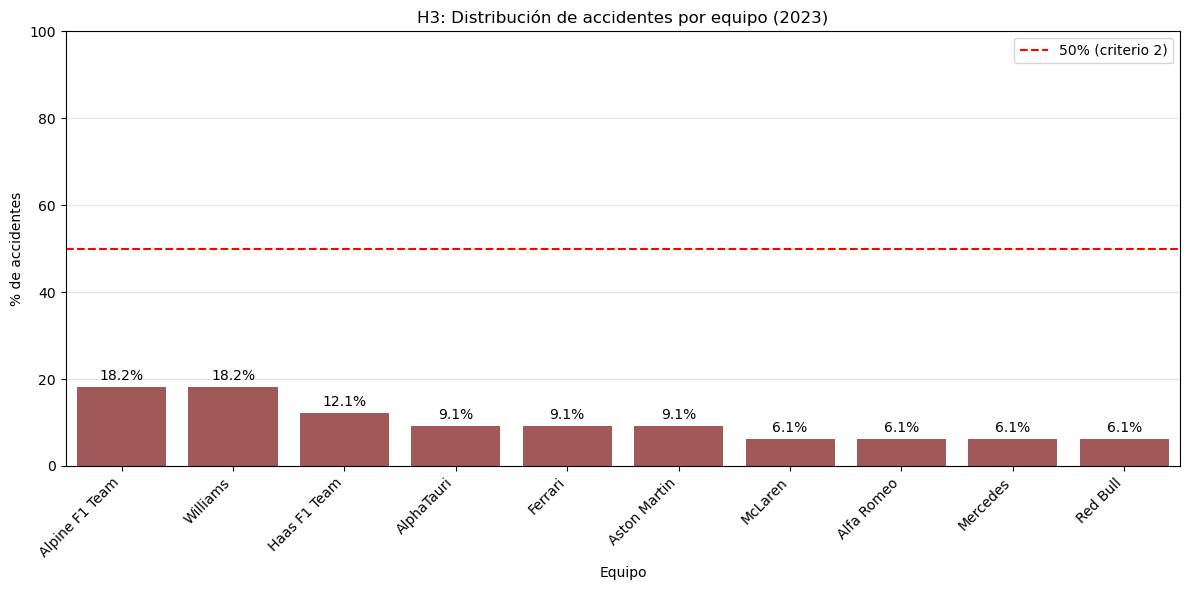

In [96]:
plt.figure(figsize=(12, 6))
ax = sns.barplot(
    x=accidentes_por_equipo_pct.index,
    y=accidentes_por_equipo_pct,
    color='darkred',
    alpha=0.7
)

# Línea del 50% (criterio 2)
plt.axhline(y=50, color='red', linestyle='--', label='50% (criterio 2)')

# Destacar top-3
for i, pct in enumerate(accidentes_por_equipo_pct):
    ax.text(i, pct + 1, f'{pct:.1f}%', ha='center', va='bottom')

plt.title('H3: Distribución de accidentes por equipo (2023)')
plt.xlabel('Equipo')
plt.ylabel('% de accidentes')
plt.ylim(0, 100)
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

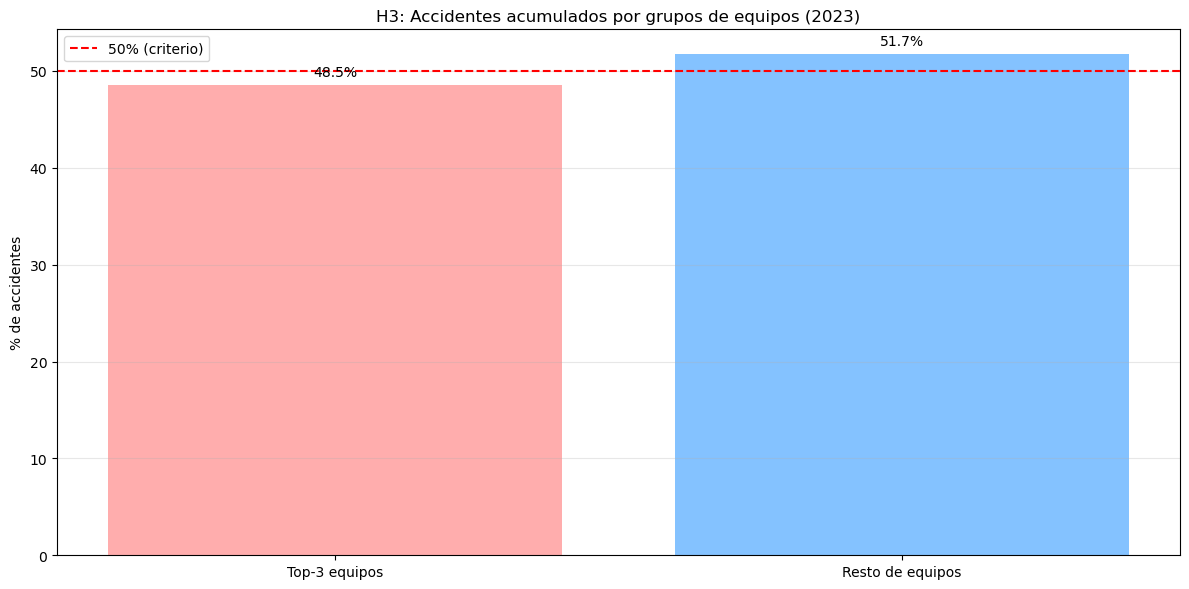

In [97]:
# Ordenar equipos por % de accidentes
equipos_ordenados = accidentes_por_equipo_pct.index
accidentes_ordenados = accidentes_por_equipo_pct.sort_values(ascending=False)

plt.figure(figsize=(12, 6))
# Barras apiladas (top-3 vs. el resto)
top3_accidentes = accidentes_ordenados.head(3)
resto_accidentes = accidentes_ordenados.tail(7).sum()
plt.bar(['Top-3 equipos', 'Resto de equipos'], [top3_accidentes.sum(), resto_accidentes], color=['#ff9999', '#66b3ff'], alpha=0.8)

# Añadir valores
plt.text(0, top3_accidentes.sum() + 1, f'{top3_accidentes.sum():.1f}%', ha='center')
plt.text(1, resto_accidentes + 1, f'{resto_accidentes:.1f}%', ha='center')

# Línea del 50% (umbral)
plt.axhline(y=50, color='red', linestyle='--', label='50% (criterio)')

plt.title('H3: Accidentes acumulados por grupos de equipos (2023)')
plt.ylabel('% de accidentes')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

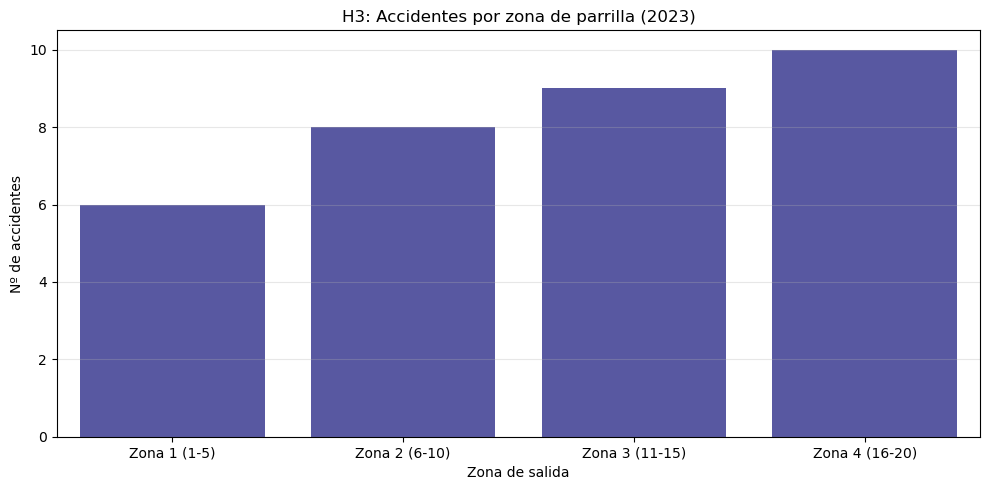

In [98]:
# Accidentes por zona (conteo absoluto)
accidentes_por_zona_count = accidentes_23['zona'].value_counts().reindex(labels)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=accidentes_por_zona_count.index,
    y=accidentes_por_zona_count,
    color='darkblue',
    alpha=0.7
)

plt.title('H3: Accidentes por zona de parrilla (2023)')
plt.xlabel('Zona de salida')
plt.ylabel('Nº de accidentes')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

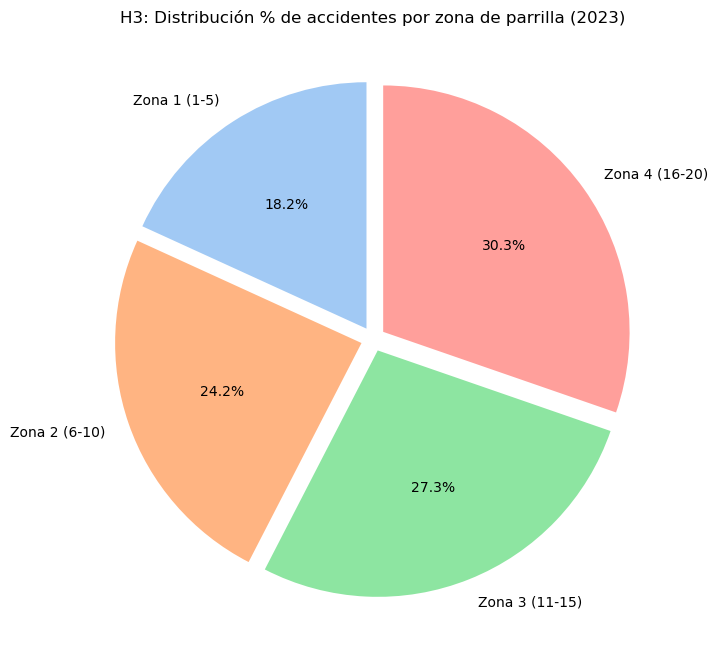

In [99]:
# Calcular % por zona
accidentes_por_zona_count = accidentes_23['zona'].value_counts().reindex(labels)
accidentes_por_zona_pct = (accidentes_por_zona_count / accidentes_por_zona_count.sum()) * 100

plt.figure(figsize=(8, 8))
plt.pie(
    accidentes_por_zona_pct,
    labels=labels,
    autopct='%1.1f%%',  # Muestra % con 1 decimal
    colors=sns.color_palette('pastel')[0:4],  # 4 colores pastel
    startangle=90,  # Empieza en la zona 1 (12 en punto)
    explode=[0.05, 0.05, 0.05, 0.05]  # Separa ligeramente cada sector
)

plt.title('H3: Distribución % de accidentes por zona de parrilla (2023)')
plt.show()

C:\Users\borja\AppData\Local\Temp\ipykernel_368496\2276214567.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(


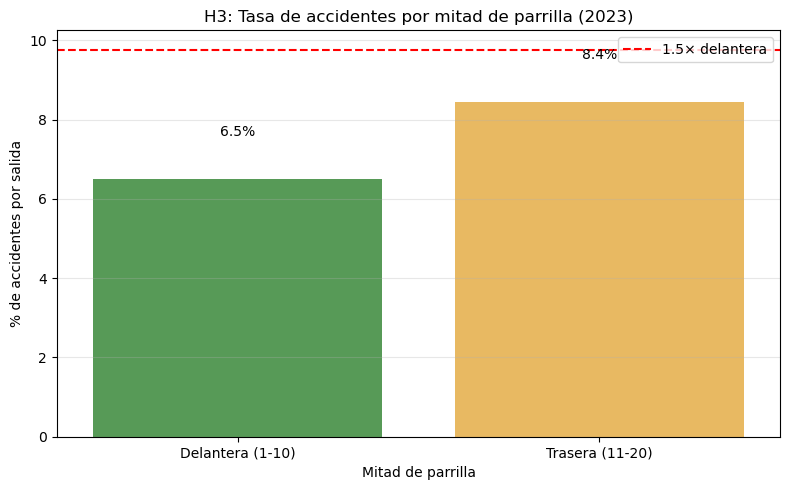

In [100]:
# Datos para el gráfico
zonas_agrupadas = ['Delantera (1-10)', 'Trasera (11-20)']
accidentes_agrupados = [accidentes_delantera, accidentes_trasera]
salidas_agrupadas = [salidas_delantera, salidas_trasera]

plt.figure(figsize=(8, 5))
bars = sns.barplot(
    x=zonas_agrupadas,
    y=[tasa_delantera * 100, tasa_trasera * 100],  # Convertir a %
    palette=['green', 'orange'],
    alpha=0.7
)

# Añadir valores en las barras
for i, (acc, sal, tasa) in enumerate(zip(accidentes_agrupados, salidas_agrupadas, [tasa_delantera, tasa_trasera])):
    bars.text(i, tasa * 100 + 1, f'{tasa:.1%}', ha='center', va='bottom')

# Línea del 1.5x (criterio 4)
plt.axhline(y=tasa_delantera * 100 * 1.5, color='red', linestyle='--', label='1.5× delantera')

plt.title('H3: Tasa de accidentes por mitad de parrilla (2023)')
plt.xlabel('Mitad de parrilla')
plt.ylabel('% de accidentes por salida')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

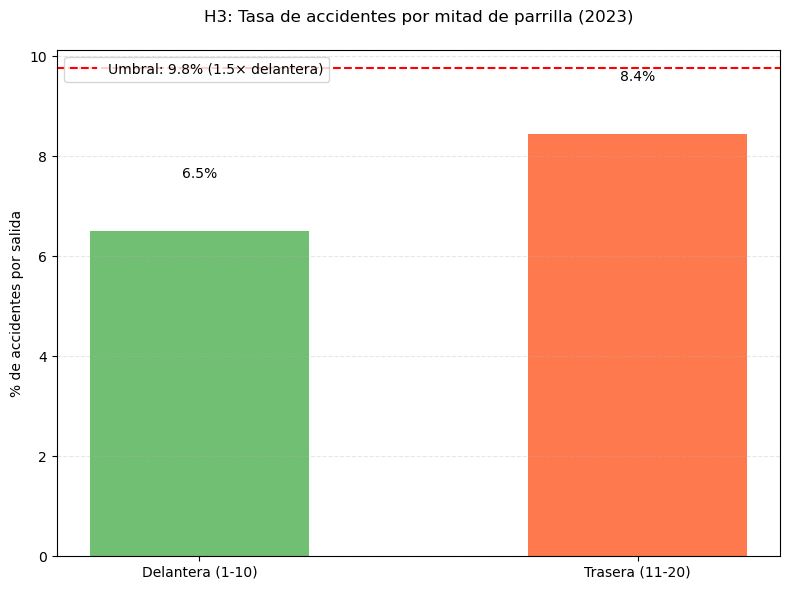

In [101]:
plt.figure(figsize=(8, 6))

# Datos
mitades = ['Delantera (1-10)', 'Trasera (11-20)']
tasas = [tasa_delantera * 100, tasa_trasera * 100]  # Convertir a %
colors = ['#4CAF50', '#FF5722']  # Verde (delantera), Naranja (trasera)

# Barras
bars = plt.bar(mitades, tasas, color=colors, alpha=0.8, width=0.5)

# Añadir valores sobre las barras
for bar, tasa in zip(bars, tasas):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 1,
             f'{tasa:.1f}%', ha='center', va='bottom', fontsize=10)

# Línea del umbral (1.5x la delantera)
umbral = tasa_delantera * 100 * 1.5
plt.axhline(y=umbral, color='red', linestyle='--',
            label=f'Umbral: {umbral:.1f}% (1.5× delantera)')

# Ajustes visuales
plt.title('H3: Tasa de accidentes por mitad de parrilla (2023)', pad=20)
plt.ylabel('% de accidentes por salida')
plt.ylim(0, max(tasas) * 1.2)  # Escala automática con margen
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.legend()
plt.tight_layout()
plt.show()

In [102]:
# --- CRUCE EXPLORATORIO: Zona habitual vs. Zona real del accidente ---
# 1. Calcular media de grid por equipo (zona habitual)
media_grid_equipo = results_23.groupby('name')['grid'].mean()

# 2. Asignar zona habitual a cada equipo
bins = [1, 6, 11, 16, 21]
labels = ['Zona 1 (1-5)', 'Zona 2 (6-10)', 'Zona 3 (11-15)', 'Zona 4 (16-20)']
zona_habitual_equipo = pd.cut(media_grid_equipo, bins=bins, labels=labels, right=False, include_lowest=True)

# 3. Mapear zona habitual a cada accidente
accidentes_23['zona_habitual'] = accidentes_23['name'].map(zona_habitual_equipo)

# 4. Tabla de contingencia: zona habitual vs. zona real
tabla_cruce = pd.crosstab(
    index=accidentes_23['zona_habitual'],
    columns=accidentes_23['zona'],
    values=accidentes_23.index,
    aggfunc='count'
).fillna(0).astype(int)

print("=== CRUCE EXPLORATORIO: Zona habitual vs. Zona real ===")
print(tabla_cruce)
print("\n--- Media de grid por equipo (2023) ---")
print(media_grid_equipo.sort_values())
print("\nInterpretación:")
print("- Diagonal: accidentes en la zona donde el equipo suele clasificarse")
print("- Fuera de diagonal: accidentes fuera de su zona habitual")
print("- Si dentro de una misma zona todos los equipos tienen valores similares → manda la parrilla")
print("- Si hay equipos que destacan (más accidentes) en su zona → manda el equipo")

=== CRUCE EXPLORATORIO: Zona habitual vs. Zona real ===
zona            Zona 1 (1-5)  Zona 2 (6-10)  Zona 3 (11-15)  Zona 4 (16-20)
zona_habitual                                                              
Zona 1 (1-5)               1              4               0               0
Zona 2 (6-10)              4              3               4               2
Zona 3 (11-15)             1              1               5               8

--- Media de grid por equipo (2023) ---
name
Ferrari            5.318182
Red Bull           5.318182
Mercedes           6.272727
Aston Martin       8.068182
McLaren            8.795455
Alpine F1 Team    10.772727
Haas F1 Team      11.113636
Alfa Romeo        13.886364
Williams          13.931818
AlphaTauri        13.977273
Name: grid, dtype: float64

Interpretación:
- Diagonal: accidentes en la zona donde el equipo suele clasificarse
- Fuera de diagonal: accidentes fuera de su zona habitual
- Si dentro de una misma zona todos los equipos tienen valores simi

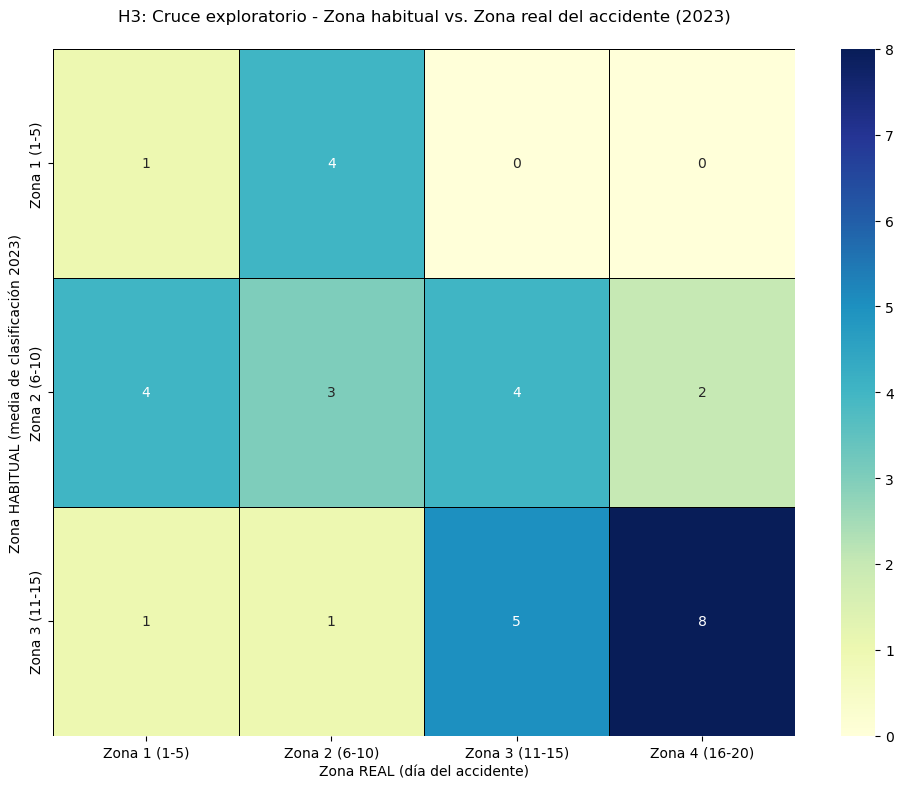

In [103]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    tabla_cruce,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    linewidths=0.5,
    linecolor='black'
)
plt.title('H3: Cruce exploratorio - Zona habitual vs. Zona real del accidente (2023)', pad=20)
plt.xlabel('Zona REAL (día del accidente)')
plt.ylabel('Zona HABITUAL (media de clasificación 2023)')
plt.tight_layout()
plt.show()

<Figure size 1200x600 with 0 Axes>

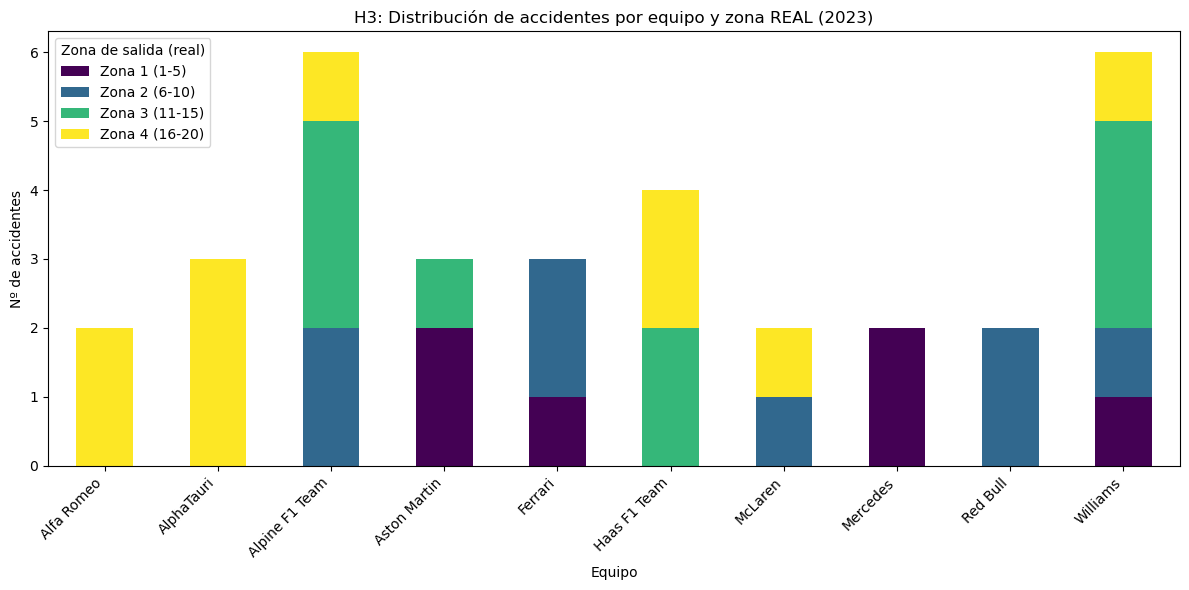

In [104]:
# Contar accidentes por equipo y zona real
accidentes_por_equipo_zona = accidentes_23.groupby(['name', 'zona']).size().unstack(fill_value=0)

plt.figure(figsize=(12, 6))
accidentes_por_equipo_zona.plot(
    kind='bar',
    stacked=True,
    colormap='viridis',
    figsize=(12, 6)
)
plt.title('H3: Distribución de accidentes por equipo y zona REAL (2023)')
plt.xlabel('Equipo')
plt.ylabel('Nº de accidentes')
plt.legend(title='Zona de salida (real)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

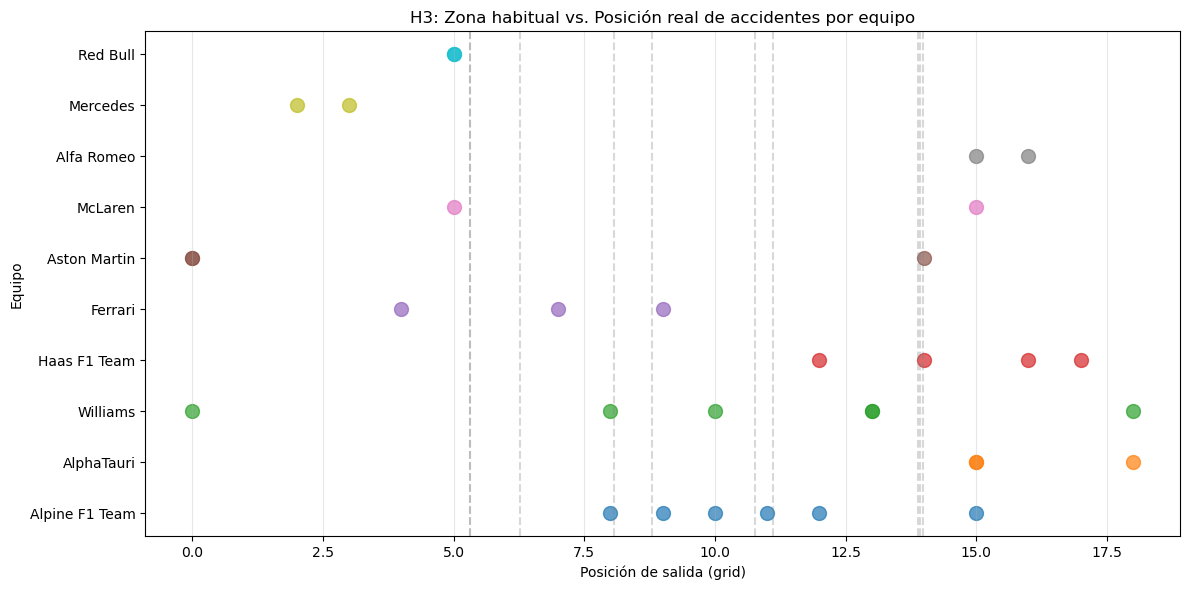

In [105]:
plt.figure(figsize=(12, 6))
for equipo in accidentes_23['name'].unique():
    datos_equipo = accidentes_23[accidentes_23['name'] == equipo]
    zona_habitual = media_grid_equipo[equipo]
    plt.axvline(x=zona_habitual, color='gray', linestyle='--', alpha=0.3)
    plt.scatter(
        datos_equipo['grid'],
        [equipo]*len(datos_equipo),
        label=equipo,
        s=100,
        alpha=0.7
    )
plt.title('H3: Zona habitual vs. Posición real de accidentes por equipo')
plt.xlabel('Posición de salida (grid)')
plt.ylabel('Equipo')
plt.yticks(range(len(accidentes_23['name'].unique())), accidentes_23['name'].unique())
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()